# BÀI TẬP 5: TRỰC QUAN HÓA CHUYÊN SÂU CHUỖI THỜI GIAN (ADVANCED TIME SERIES EDA)
**Môn học:** Quản lý & Khai phá Chuỗi Thời Gian (QLCTG)  
**Nhóm thực hiện:** Nhóm 07  

---
### Mục tiêu bài tập:
1. Phân tích Rolling Statistics (window=12): Rolling Mean và dải $\pm 2$ Rolling Std để phát hiện phương sai thay đổi (Heteroskedasticity).
2. Vẽ biểu đồ mùa vụ theo từng tháng qua các năm (Monthly Seasonal Plot).
3. Xây dựng bản đồ nhiệt chu kỳ mùa vụ (Seasonality Heatmap: Ma trận Năm $\times$ Tháng).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

DATA_PATH = Path("../data/raw/AirPassengers.csv")
FIGURES_DIR = Path("../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


### Bước 1: Nạp và tính toán thống kê trượt


In [2]:
df = pd.read_csv(DATA_PATH)
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)
series = df['Passengers'].astype(float).asfreq('MS')

# Rolling statistics (window=12)
rolling_mean = series.rolling(window=12).mean()
rolling_std = series.rolling(window=12).std()
upper_band = rolling_mean + 2 * rolling_std
lower_band = rolling_mean - 2 * rolling_std

valid = (~rolling_mean.isna()).sum()
inside_band = ((series >= lower_band) & (series <= upper_band)).sum()
coverage = inside_band / valid * 100
print(f"Tỉ lệ điểm nằm trong dải +/- 2 Std: {coverage:.1f}% (~95% chuẩn thực nghiệm)")


Tỉ lệ điểm nằm trong dải +/- 2 Std: 95.5% (~95% chuẩn thực nghiệm)


### Bước 2: Tái cấu trúc ma trận Pivot (Năm x Tháng)


In [3]:
df_pivot = series.to_frame(name="Passengers").copy()
df_pivot['Year'] = df_pivot.index.year
df_pivot['Month_Num'] = df_pivot.index.month

pivot_table = df_pivot.pivot(index='Year', columns='Month_Num', values='Passengers')
monthly_avg = df_pivot.groupby('Month_Num')['Passengers'].mean()

print(f"Đỉnh hành khách trong năm: Tháng {monthly_avg.idxmax()} (TB {monthly_avg.max():.1f} nghìn người)")
print(f"Đáy hành khách trong năm:  Tháng {monthly_avg.idxmin()} (TB {monthly_avg.min():.1f} nghìn người)")


Đỉnh hành khách trong năm: Tháng 7 (TB 351.3 nghìn người)
Đáy hành khách trong năm:  Tháng 11 (TB 232.8 nghìn người)


### Bước 3: Kết xuất 3 biểu đồ trực quan hóa chuyên sâu


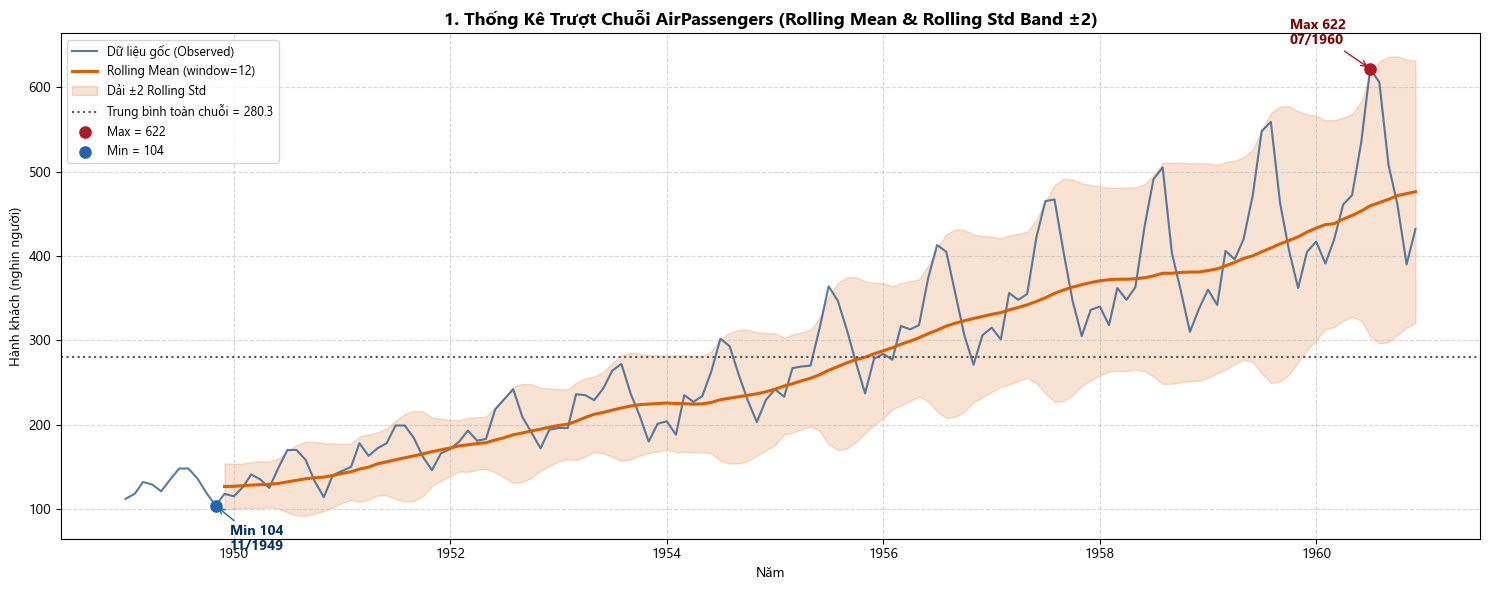

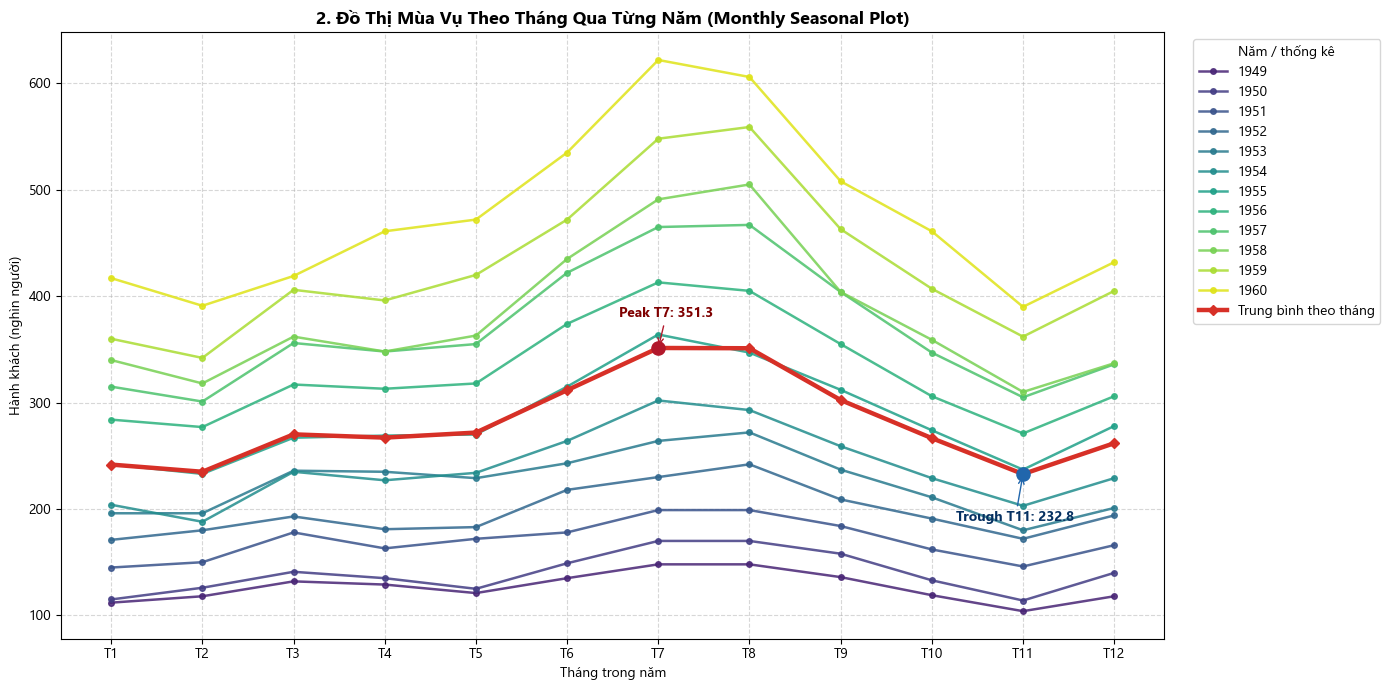

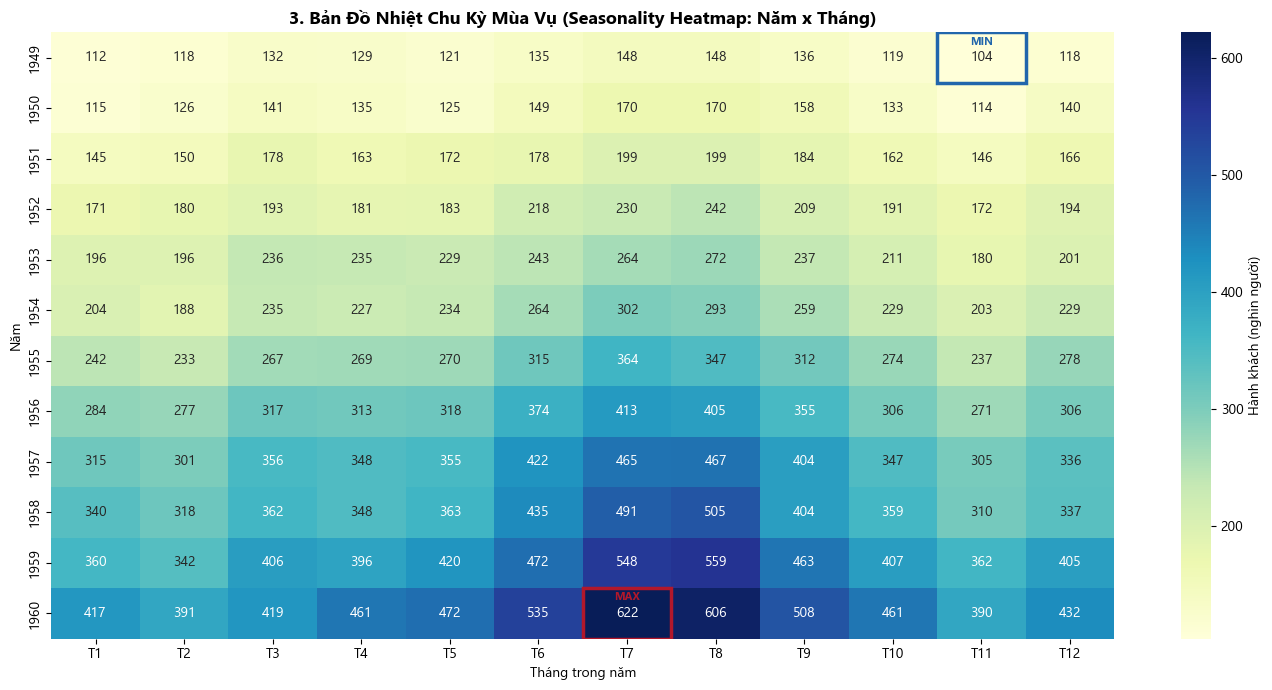

In [4]:
# Tạo các thống kê dùng chung cho chú thích trên cả ba biểu đồ
overall_mean = series.mean()
max_date = series.idxmax()
min_date = series.idxmin()
max_value = series.max()
min_value = series.min()
peak_month = monthly_avg.idxmax()
trough_month = monthly_avg.idxmin()

# 1. Rolling Statistics Plot
fig1, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(
    series.index,
    series.values,
    label="Dữ liệu gốc (Observed)",
    color="#2b5c8f",
    lw=1.5,
    alpha=0.8,
)
ax1.plot(
    series.index,
    rolling_mean,
    label="Rolling Mean (window=12)",
    color="#d95f02",
    lw=2.2,
)
ax1.fill_between(
    series.index,
    lower_band,
    upper_band,
    color="#d95f02",
    alpha=0.18,
    label="Dải ±2 Rolling Std",
)

# Đường trung bình toàn chuỗi và đánh dấu min/max thực tế
ax1.axhline(
    overall_mean,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label=f"Trung bình toàn chuỗi = {overall_mean:.1f}",
)
ax1.scatter(
    [max_date],
    [max_value],
    color="#b2182b",
    s=65,
    zorder=5,
    label=f"Max = {max_value:.0f}",
)
ax1.scatter(
    [min_date],
    [min_value],
    color="#2166ac",
    s=65,
    zorder=5,
    label=f"Min = {min_value:.0f}",
)
ax1.annotate(
    f"Max {max_value:.0f}\n{max_date:%m/%Y}",
    xy=(max_date, max_value),
    xytext=(-58, 18),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#b2182b"},
    color="#7f0000",
    fontweight="bold",
)
ax1.annotate(
    f"Min {min_value:.0f}\n{min_date:%m/%Y}",
    xy=(min_date, min_value),
    xytext=(10, -32),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#2166ac"},
    color="#053061",
    fontweight="bold",
)
ax1.set_title(
    "1. Thống Kê Trượt Chuỗi AirPassengers "
    "(Rolling Mean & Rolling Std Band ±2)",
    fontsize=13,
    fontweight="bold",
)
ax1.set_xlabel("Năm")
ax1.set_ylabel("Hành khách (nghìn người)")
ax1.legend(loc="upper left", fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
fig1.savefig(FIGURES_DIR / "bai5_1_rolling_statistics.png", dpi=300)
plt.show()

# 2. Monthly Seasonal Plot
fig2, ax2 = plt.subplots(figsize=(14, 7))
month_names = [
    "T1", "T2", "T3", "T4", "T5", "T6",
    "T7", "T8", "T9", "T10", "T11", "T12",
]
colors = plt.cm.viridis(np.linspace(0.1, 0.95, len(pivot_table.index)))
for idx, year in enumerate(pivot_table.index):
    ax2.plot(
        range(1, 13),
        pivot_table.loc[year],
        marker="o",
        label=str(year),
        color=colors[idx],
        lw=1.8,
        markersize=4,
        alpha=0.85,
    )

# Đường trung bình theo tháng, giúp so sánh mùa vụ tổng quát
ax2.plot(
    range(1, 13),
    monthly_avg,
    color="#d73027",
    linewidth=3.2,
    marker="D",
    markersize=5,
    label="Trung bình theo tháng",
    zorder=6,
)
ax2.scatter(
    [peak_month],
    [monthly_avg.loc[peak_month]],
    color="#b2182b",
    s=90,
    zorder=7,
)
ax2.scatter(
    [trough_month],
    [monthly_avg.loc[trough_month]],
    color="#2166ac",
    s=90,
    zorder=7,
)
ax2.annotate(
    f"Peak T{peak_month}: {monthly_avg.loc[peak_month]:.1f}",
    xy=(peak_month, monthly_avg.loc[peak_month]),
    xytext=(-28, 22),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#b2182b"},
    color="#7f0000",
    fontweight="bold",
)
ax2.annotate(
    f"Trough T{trough_month}: {monthly_avg.loc[trough_month]:.1f}",
    xy=(trough_month, monthly_avg.loc[trough_month]),
    xytext=(-48, -34),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#2166ac"},
    color="#053061",
    fontweight="bold",
)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(month_names)
ax2.set_title(
    "2. Đồ Thị Mùa Vụ Theo Tháng Qua Từng Năm "
    "(Monthly Seasonal Plot)",
    fontsize=13,
    fontweight="bold",
)
ax2.set_xlabel("Tháng trong năm")
ax2.set_ylabel("Hành khách (nghìn người)")
ax2.legend(title="Năm / thống kê", bbox_to_anchor=(1.02, 1), loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
fig2.savefig(FIGURES_DIR / "bai5_2_seasonal_plot.png", dpi=300)
plt.show()

# 3. Seasonality Heatmap
fig3, ax3 = plt.subplots(figsize=(14, 7))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={"label": "Hành khách (nghìn người)"},
    ax=ax3,
)

# Khoanh ô có giá trị lớn nhất và nhỏ nhất trên ma trận Year x Month
max_position = np.unravel_index(np.nanargmax(pivot_table.to_numpy()), pivot_table.shape)
min_position = np.unravel_index(np.nanargmin(pivot_table.to_numpy()), pivot_table.shape)
for row, col, color, label in [
    (*max_position, "#b2182b", "MAX"),
    (*min_position, "#2166ac", "MIN"),
]:
    ax3.add_patch(
        plt.Rectangle(
            (col, row),
            1,
            1,
            fill=False,
            edgecolor=color,
            linewidth=2.5,
        )
    )
    ax3.text(
        col + 0.5,
        row + 0.18,
        label,
        ha="center",
        va="center",
        color=color,
        fontsize=8,
        fontweight="bold",
    )

ax3.set_xticklabels(month_names)
ax3.set_title(
    "3. Bản Đồ Nhiệt Chu Kỳ Mùa Vụ "
    "(Seasonality Heatmap: Năm x Tháng)",
    fontsize=13,
    fontweight="bold",
)
ax3.set_xlabel("Tháng trong năm")
ax3.set_ylabel("Năm")
plt.tight_layout()
fig3.savefig(FIGURES_DIR / "bai5_3_seasonality_heatmap.png", dpi=300)
plt.show()


### Bước 4: Nhận xét và Kết luận
1. **Xu hướng và Phương sai:** Đường Rolling Mean thể hiện xu hướng tăng trưởng dốc và ổn định từ 1949 đến 1960 (+275.9%). Dải $\pm 2$ Std phình rộng gấp 5.67 lần (từ 13.72 năm 1949 lên 77.74 năm 1960), minh chứng phương sai thay đổi (Heteroskedasticity).
2. **Quy luật Mùa vụ:** 12 đường cong mùa vụ tịnh tiến đồng dạng hoàn hảo, đỉnh điểm luôn là Tháng 7 (du lịch hè) và đáy thấp nhất luôn là Tháng 11.
3. **Bản đồ nhiệt:** Heatmap 12x12 làm nổi bật hai chiều thông tin cùng lúc: "dải màu nóng" Tháng 7 - Tháng 8 (mùa vụ) và gradient tăng dần từ nhạt sang đậm theo trục năm (xu hướng dài hạn).
